# [Student] 🐼 Pandas for Data Analysis: Basics + Customer Churn Project
**Section 1:** learn pandas functions and attributes on small examples (no file needed).  
**Section 2:** a real project on `customer_churn.csv`: clean → explore → visualise → model.

---
## Section 2 preview: the story
### 🎬 The story
You've just joined **KeralaNet Broadband** as a junior data analyst. On day one your manager drops a file on your desk:

> *"We're losing customers every month and nobody knows why. Here's our customer data, `customer_churn.csv`. Find out **who** is leaving, **why** they leave, and build something that can **warn us early**."*

Section 2 of this notebook is your project. Work through Parts A–F. Each ✏️ **Question** has an empty code cell for your answer. 💡 **Business insight** cells ask you to explain what the numbers mean, in plain words, as you would to your manager.

| Part | What you'll do |
|---|---|
| A | Meet the data |
| B | Clean the data |
| C | EDA: answer the manager's questions |
| C2 | Visualising with Matplotlib |
| D | Prepare the data for a model |
| E | Build a logistic regression model |
| F | Recommendations and challenges |

You only need `customer_churn.csv` from **Section 2** onwards. Section 1 needs no files.

## Setup (run this cell)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (8, 4)

---
# 📘 SECTION 1: Pandas Basics
Before the project, let's learn the main **functions, attributes and methods** of pandas on small tables we type in ourselves. **No CSV is needed for this section.**

> **Attribute** is a fact about an object; there are no brackets: `df.shape`, `s.size`
> **Method** is an action; it needs brackets: `df.head()`, `s.mean()`
> **Function** is called from `pd`: `pd.Series()`, `pd.DataFrame()`, `pd.read_csv()`

## 1.1 Series: a single column of data

In [ ]:
prices = pd.Series([120, 40, 90, 50], index=["Mango", "Banana", "Jackfruit", "Papaya"])
prices

,0
Mango,120
Banana,40
Jackfruit,90
Papaya,50


In [ ]:
# Attributes (no brackets)
print("size     :", prices.size)
print("dtype    :", prices.dtype)
print("index    :", list(prices.index))
print("values   :", prices.values)
print("is_unique:", prices.is_unique)

size     : 4
dtype    : int64
index    : ['Mango', 'Banana', 'Jackfruit', 'Papaya']
values   : [120  40  90  50]
is_unique: True


In [ ]:
# Methods (with brackets)
print("sum :", prices.sum())
print("mean:", prices.mean())
print("max :", prices.max(), "| idxmax:", prices.idxmax())
prices.sort_values(ascending=False)

sum : 300
mean: 75.0
max : 120 | idxmax: Mango


,0
Mango,120
Jackfruit,90
Papaya,50
Banana,40


### ✏️ Question 1.1a
Create a Series `marks` from a **dictionary**: `{'Anu': 78, 'Ben': 92, 'Chitra': 65, 'Dev': 88, 'Esha': 92}`. Print its `size`, `mean()`, `median()`, `mode()` and `is_unique`.

In [ ]:
marks = pd.Series({
    "Anu": 78,
    "Ben": 92,
    "Chitra": 65,
    "Dev": 88,
    "Esha": 92,
})

print("size:", marks.size)
print("mean:", marks.mean())
print("median:", marks.median())
print("mode:", marks.mode().tolist())
print("is_unique:", marks.is_unique)

size: 5
mean: 83.0
median: 88.0
mode: [92]
is_unique: False


### ✏️ Question 1.1b
Who scored the highest and the lowest in `marks`? Sort the marks from highest to lowest.

In [ ]:
print("Highest:", marks.idxmax(), marks.max())
print("Lowest:", marks.idxmin(), marks.min())
print(marks.sort_values(ascending=False))

Highest: Ben 92
Lowest: Chitra 65
Ben       92
Esha      92
Dev       88
Anu       78
Chitra    65
dtype: int64


## 1.2 Selecting values: `iloc`, `loc`, `get`
- `iloc[...]` selects by **position** (0, 1, 2…)
- `loc[...]` selects by **label**
- `get(label, default)` selects by label without raising an error if the label is missing

In [ ]:
print(prices.iloc[0])            # first value
print(prices.loc["Banana"])       # by label
print(prices.iloc[1:3])           # positions 1 and 2
print(prices.get("Apple", "Not found"))

120
40
Banana       40
Jackfruit    90
dtype: int64
Not found


### ✏️ Question 1.2a
From `marks`, get (a) the 3rd value by position, (b) Dev's mark by label, (c) the last two values, (d) `'Farah'` with a default of `0`.

In [ ]:
print("3rd value:", marks.iloc[2])
print("Dev's mark:", marks.loc["Dev"])
print("Last two:\n", marks.iloc[-2:])
print("Farah:", marks.get("Farah", 0))

3rd value: 65
Dev's mark: 88
Last two:
 Dev     88
Esha    92
dtype: int64
Farah: 0


## 1.3 Broadcasting, `value_counts`, `apply`, `map`

In [ ]:
print(prices * 1.18)          # one operation applied to every value (add 18% GST)

colours = pd.Series(["Red", "Blue", "Red", "Green", "Red", "Blue"])
print(colours.value_counts())
print(colours.value_counts(normalize=True))   # proportions

Mango        141.6
Banana        47.2
Jackfruit    106.2
Papaya        59.0
dtype: float64
Red      3
Blue     2
Green    1
Name: count, dtype: int64
Red      0.500000
Blue     0.333333
Green    0.166667
Name: proportion, dtype: float64


In [ ]:
def grade(m):
    return "A" if m >= 90 else "B" if m >= 75 else "C"

print(marks.apply(grade))                                # apply runs a function on every value
print(colours.map({"Red": "R", "Blue": "B", "Green": "G"}))   # map swaps values using a dict

Anu       B
Ben       A
Chitra    C
Dev       B
Esha      A
dtype: object
0    R
1    B
2    R
3    G
4    R
5    B
dtype: object


### ✏️ Question 1.3a
Give every student in `marks` 5 grace marks, then use `apply(grade)` to find each student's grade. How many students got each grade?

In [ ]:
grace_marks = marks + 5
grades = grace_marks.apply(grade)
print(grades)
print("\nGrade counts:")
print(grades.value_counts())

Anu       B
Ben       A
Chitra    C
Dev       A
Esha      A
dtype: object

Grade counts:
A    3
B    1
C    1
Name: count, dtype: int64


## 1.4 DataFrames: a table of Series

In [ ]:
emp = pd.DataFrame({
    "Name":   ["Asha", "Ravi", "Meera", "John", "Fathima", "Kiran", "Ravi"],
    "Dept":   ["IT", "HR", "IT", "Sales", "HR", "Sales", "HR"],
    "Age":    [28, 35, None, 42, 30, 25, 35],
    "Salary": [55000, 48000, 62000, 70000, None, 39000, 48000],
    "City":   [" kochi", "Thrissur", "KOCHI ", "Kollam", "thrissur", "Kochi", "Thrissur"],
    "Joined": ["2021-03-15", "2018-07-01", "2020-01-10", "2015-11-20", "2022-05-05", "2023-02-01", "2018-07-01"],
})
emp

,Name,Dept,Age,Salary,City,Joined
0,Asha,IT,28.0,55000.0,kochi,2021-03-15
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01
2,Meera,IT,NaN,62000.0,KOCHI,2020-01-10
3,John,Sales,42.0,70000.0,Kollam,2015-11-20
4,Fathima,HR,30.0,NaN,thrissur,2022-05-05
5,Kiran,Sales,25.0,39000.0,Kochi,2023-02-01
6,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01


In [ ]:
# Attributes
print("shape  :", emp.shape)
print("columns:", list(emp.columns))
print("index  :", emp.index)
print(emp.dtypes)

shape  : (7, 6)
columns: ['Name', 'Dept', 'Age', 'Salary', 'City', 'Joined']
index  : RangeIndex(start=0, stop=7, step=1)
Name       object
Dept       object
Age       float64
Salary    float64
City       object
Joined     object
dtype: object


In [ ]:
emp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Name    7 non-null      object 
 1   Dept    7 non-null      object 
 2   Age     6 non-null      float64
 3   Salary  6 non-null      float64
 4   City    7 non-null      object 
 5   Joined  7 non-null      object 
dtypes: float64(2), object(4)
memory usage: 468.0+ bytes


In [ ]:
emp.describe()

,Age,Salary
count,6.000000,6.000000
mean,32.500000,53666.666667
std,6.090977,11111.555547
min,25.000000,39000.000000
25%,28.500000,48000.000000
50%,32.500000,51500.000000
75%,35.000000,60250.000000
max,42.000000,70000.000000


### ✏️ Question 1.4a
Show the first 3 rows and the last 2 rows of `emp`. How many rows and columns does it have?

In [ ]:
print("First 3 rows:\n", emp.head(3))
print("\nLast 2 rows:\n", emp.tail(2))
print("\nShape (rows, cols):", emp.shape)

First 3 rows:
     Name Dept   Age   Salary      City      Joined
0   Asha   IT  28.0  55000.0     kochi  2021-03-15
1   Ravi   HR  35.0  48000.0  Thrissur  2018-07-01
2  Meera   IT   NaN  62000.0    KOCHI   2020-01-10

Last 2 rows:
     Name   Dept   Age   Salary      City      Joined
5  Kiran  Sales  25.0  39000.0     Kochi  2023-02-01
6   Ravi     HR  35.0  48000.0  Thrissur  2018-07-01

Shape (rows, cols): (7, 6)


## 1.5 Working with columns

In [ ]:
print(type(emp["Name"]))          # one column gives a Series
emp[["Name", "Salary"]]           # a list of columns gives a DataFrame

<class 'pandas.core.series.Series'>


,Name,Salary
0,Asha,55000.0
1,Ravi,48000.0
2,Meera,62000.0
3,John,70000.0
4,Fathima,NaN
5,Kiran,39000.0
6,Ravi,48000.0


In [ ]:
emp["Bonus"] = emp["Salary"] * 0.10                     # add a column
emp = emp.rename(columns={"Dept": "Department"})        # rename a column
emp.head(3)

,Name,Department,Age,Salary,City,Joined,Bonus
0,Asha,IT,28.0,55000.0,kochi,2021-03-15,5500.0
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01,4800.0
2,Meera,IT,NaN,62000.0,KOCHI,2020-01-10,6200.0


In [ ]:
emp = emp.drop(columns="Bonus")                         # drop a column
emp["Department"] = emp["Department"].astype("category") # change the dtype
emp.dtypes

,0
Name,object
Department,category
Age,float64
Salary,float64
City,object
Joined,object


### ✏️ Question 1.5a
Add a column `Salary_Lakhs` = `Salary / 100000`, rounded to 2 decimals. Show only `Name` and `Salary_Lakhs`.

In [ ]:
emp["Salary_Lakhs"] = (emp["Salary"] / 100000).round(2)
print(emp[["Name", "Salary_Lakhs"]])

      Name  Salary_Lakhs
0     Asha          0.55
1     Ravi          0.48
2    Meera          0.62
3     John          0.70
4  Fathima           NaN
5    Kiran          0.39
6     Ravi          0.48


## 1.6 Filtering rows
A filter is a **True/False Series** placed inside `df[...]`. Combine filters with `&` (AND), `|` (OR) and `~` (NOT), and always put brackets around each condition.

In [ ]:
emp[emp["Age"] > 30]

,Name,Department,Age,Salary,City,Joined,Salary_Lakhs
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01,0.48
3,John,Sales,42.0,70000.0,Kollam,2015-11-20,0.70
6,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01,0.48


In [ ]:
emp[(emp["Department"] == "HR") & (emp["Salary"] > 45000)]

,Name,Department,Age,Salary,City,Joined,Salary_Lakhs
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01,0.48
6,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01,0.48


In [ ]:
print(emp[emp["Department"].isin(["IT", "Sales"])]["Name"].tolist())
print(emp[emp["Age"].between(25, 32)]["Name"].tolist())
emp[emp["Salary"].isnull()]

['Asha', 'Meera', 'John', 'Kiran']
['Asha', 'Fathima', 'Kiran']


,Name,Department,Age,Salary,City,Joined,Salary_Lakhs
4,Fathima,HR,30.0,NaN,thrissur,2022-05-05,NaN


### ✏️ Question 1.6a
Find the employees who work in **IT or Sales** and earn **more than 50,000**.

In [ ]:
filtered_emp = emp[(emp["Department"].isin(["IT", "Sales"])) & (emp["Salary"] > 50000)]
print(filtered_emp)

    Name Department   Age   Salary    City      Joined  Salary_Lakhs
0   Asha         IT  28.0  55000.0   kochi  2021-03-15          0.55
2  Meera         IT   NaN  62000.0  KOCHI   2020-01-10          0.62
3   John      Sales  42.0  70000.0  Kollam  2015-11-20          0.70


## 1.7 Missing values and duplicates

In [ ]:
print(emp.isnull().sum())
print("Duplicate rows:", emp.duplicated().sum())

Name            0
Department      0
Age             1
Salary          1
City            0
Joined          0
Salary_Lakhs    1
dtype: int64
Duplicate rows: 1


In [ ]:
clean = emp.drop_duplicates().copy()
clean["Age"] = clean["Age"].fillna(clean["Age"].median())
clean["Salary"] = clean["Salary"].fillna(clean["Salary"].mean())
print(clean.isnull().sum().sum(), "missing values left")
clean

1 missing values left


,Name,Department,Age,Salary,City,Joined,Salary_Lakhs
0,Asha,IT,28.0,55000.0,kochi,2021-03-15,0.55
1,Ravi,HR,35.0,48000.0,Thrissur,2018-07-01,0.48
2,Meera,IT,30.0,62000.0,KOCHI,2020-01-10,0.62
3,John,Sales,42.0,70000.0,Kollam,2015-11-20,0.70
4,Fathima,HR,30.0,54800.0,thrissur,2022-05-05,NaN
5,Kiran,Sales,25.0,39000.0,Kochi,2023-02-01,0.39


### ✏️ Question 1.7a
Starting from `emp` again, use `dropna()` to drop every row that has **any** missing value. How many rows are left? Why might this be a bad idea in real data?

In [ ]:
emp_dropped = emp.dropna()
print("Rows left:", len(emp_dropped))

Rows left: 5


## 1.8 Text (`.str`) and dates (`.dt`)

In [ ]:
clean["City"]

,City
0,kochi
1,Thrissur
2,KOCHI
3,Kollam
4,thrissur
5,Kochi


In [ ]:
# Step 0: see the hidden spaces
# repr() shows each value in quotes, so leading/trailing spaces become visible
for city in clean["City"]:
    print(repr(city), "-> length:", len(city))

' kochi' -> length: 6
'Thrissur' -> length: 8
'KOCHI ' -> length: 6
'Kollam' -> length: 6
'thrissur' -> length: 8
'Kochi' -> length: 5


In [ ]:
# Step 1: .str gives access to string methods for every value in the column
# .str.len() counts the characters in each value (spaces count too)
clean["City"].str.len()

,City
0,6
1,8
2,6
3,6
4,8
5,5


In [ ]:
# Step 2: .str.strip() removes spaces from both ends of each value
# Compare the lengths: " kochi" (6) becomes "kochi" (5)
stripped = clean["City"].str.strip()
print(stripped.tolist())
print(stripped.str.len().tolist())

['kochi', 'Thrissur', 'KOCHI', 'Kollam', 'thrissur', 'Kochi']
[5, 8, 5, 6, 8, 5]


In [ ]:
# Step 2b: lstrip() removes spaces on the left only, rstrip() on the right only
print(clean["City"].str.lstrip().tolist())
print(clean["City"].str.rstrip().tolist())

['kochi', 'Thrissur', 'KOCHI ', 'Kollam', 'thrissur', 'Kochi']
[' kochi', 'Thrissur', 'KOCHI', 'Kollam', 'thrissur', 'Kochi']


In [ ]:
# Step 3: change the letter case
print(stripped.str.lower().tolist())   # all small letters
print(stripped.str.upper().tolist())   # all capital letters
print(stripped.str.title().tolist())   # First Letter Capital

['kochi', 'thrissur', 'kochi', 'kollam', 'thrissur', 'kochi']
['KOCHI', 'THRISSUR', 'KOCHI', 'KOLLAM', 'THRISSUR', 'KOCHI']
['Kochi', 'Thrissur', 'Kochi', 'Kollam', 'Thrissur', 'Kochi']


In [ ]:
clean["City"].str.strip()

,City
0,kochi
1,Thrissur
2,KOCHI
3,Kollam
4,thrissur
5,Kochi


In [ ]:
clean["City"].str.strip().str.title()

,City
0,Kochi
1,Thrissur
2,Kochi
3,Kollam
4,Thrissur
5,Kochi


In [ ]:
clean["City"].value_counts()

,count
City,
kochi,1
Thrissur,1
KOCHI,1
Kollam,1
thrissur,1
Kochi,1


In [ ]:
clean["City"] = clean["City"].str.strip().str.title()
print(clean["City"].value_counts())

City
Kochi       3
Thrissur    2
Kollam      1
Name: count, dtype: int64


In [ ]:
print(clean[clean["Name"].str.contains("a")]["Name"].tolist())   # names containing 'a'
print(clean["Name"].str.upper().tolist())

['Asha', 'Ravi', 'Meera', 'Fathima', 'Kiran']
['ASHA', 'RAVI', 'MEERA', 'JOHN', 'FATHIMA', 'KIRAN']


In [ ]:
clean["City"] = clean["City"].str.strip().str.title()
print(clean["City"].value_counts())
print(clean[clean["Name"].str.contains("a")]["Name"].tolist())   # names containing 'a'
print(clean["Name"].str.upper().tolist())

City
Kochi       3
Thrissur    2
Kollam      1
Name: count, dtype: int64
['Asha', 'Ravi', 'Meera', 'Fathima', 'Kiran']
['ASHA', 'RAVI', 'MEERA', 'JOHN', 'FATHIMA', 'KIRAN']


In [ ]:
clean["Joined"]

,Joined
0,2021-03-15
1,2018-07-01
2,2020-01-10
3,2015-11-20
4,2022-05-05
5,2023-02-01


In [ ]:
clean["Joined"] = pd.to_datetime(clean["Joined"])
clean["Joined"]

,Joined
0,2021-03-15
1,2018-07-01
2,2020-01-10
3,2015-11-20
4,2022-05-05
5,2023-02-01


In [ ]:
clean["JoinYear"] = clean["Joined"].dt.year
clean["JoinYear"]

,JoinYear
0,2021
1,2018
2,2020
3,2015
4,2022
5,2023


In [ ]:
clean["JoinDay"] = clean["Joined"].dt.day_name()
clean[["Name", "Joined", "JoinYear", "JoinDay"]]

,Name,Joined,JoinYear,JoinDay
0,Asha,2021-03-15,2021,Monday
1,Ravi,2018-07-01,2018,Sunday
2,Meera,2020-01-10,2020,Friday
3,John,2015-11-20,2015,Friday
4,Fathima,2022-05-05,2022,Thursday
5,Kiran,2023-02-01,2023,Wednesday


In [ ]:
clean["Joined"] = pd.to_datetime(clean["Joined"])
clean["JoinYear"] = clean["Joined"].dt.year
clean["JoinDay"] = clean["Joined"].dt.day_name()
clean[["Name", "Joined", "JoinYear", "JoinDay"]]

,Name,Joined,JoinYear,JoinDay
0,Asha,2021-03-15,2021,Monday
1,Ravi,2018-07-01,2018,Sunday
2,Meera,2020-01-10,2020,Friday
3,John,2015-11-20,2015,Friday
4,Fathima,2022-05-05,2022,Thursday
5,Kiran,2023-02-01,2023,Wednesday


### ✏️ Question 1.8a
Which employees joined **before 2020**? Show their names and joining years.

In [ ]:
emp["Joined"] = pd.to_datetime(emp["Joined"])
emp["JoinYear"] = emp["Joined"].dt.year
print(emp[emp["JoinYear"] < 2020][["Name", "JoinYear"]])

   Name  JoinYear
1  Ravi      2018
3  John      2015
6  Ravi      2018


## 1.9 Grouping and sorting

**Why `observed=True`?** It only matters when the group-by column has the `category` dtype (we converted `Department` earlier).
- `observed=True` shows only the categories that actually **appear** in the data.
- `observed=False` shows **every** category, including empty ones, with NaN.
- Writing it explicitly avoids a FutureWarning in pandas 2.x and gives the same result in pandas 3.x.

In [ ]:
clean.groupby("Department",observed=True)["Salary"].mean().round(0)

,Salary
Department,
HR,51400.0
IT,58500.0
Sales,54500.0


In [ ]:
clean.groupby("Department", observed=True).agg(
    people=("Name", "count"),
    avg_salary=("Salary", "mean"),
    oldest=("Age", "max"),
).round(0)

,people,avg_salary,oldest
Department,,,
HR,2,51400.0,35.0
IT,2,58500.0,30.0
Sales,2,54500.0,42.0


In [ ]:
print(clean.sort_values("Salary", ascending=False)[["Name", "Salary"]])
clean.nlargest(2, "Salary")[["Name", "Salary"]]

      Name   Salary
3     John  70000.0
2    Meera  62000.0
0     Asha  55000.0
4  Fathima  54800.0
1     Ravi  48000.0
5    Kiran  39000.0


,Name,Salary
3,John,70000.0
2,Meera,62000.0


### ✏️ Question 1.9a
Find the **average age per city**, sorted from highest to lowest.

In [ ]:
print(emp.groupby("City")["Age"].mean().sort_values(ascending=False))

City
Kollam      42.0
Thrissur    35.0
thrissur    30.0
 kochi      28.0
Kochi       25.0
KOCHI        NaN
Name: Age, dtype: float64


## 1.10 Loops over columns
`df.dtypes` holds every column's data type (the same information `info()` prints), so we can loop over it.

In [ ]:
for col, dtype in clean.dtypes.items():
    print(f"--- {col} ({dtype}) ---")
    if dtype == "int64" or dtype == "float64":
        print(clean[col].describe().round(1))
    else:
        print(clean[col].value_counts().head(3))

--- Name (object) ---
Name
Asha     1
Ravi     1
Meera    1
Name: count, dtype: int64
--- Department (category) ---
Department
HR       2
IT       2
Sales    2
Name: count, dtype: int64
--- Age (float64) ---
count     6.0
mean     31.7
std       6.0
min      25.0
25%      28.5
50%      30.0
75%      33.8
max      42.0
Name: Age, dtype: float64
--- Salary (float64) ---
count        6.0
mean     54800.0
std      10759.2
min      39000.0
25%      49700.0
50%      54900.0
75%      60250.0
max      70000.0
Name: Salary, dtype: float64
--- City (object) ---
City
Kochi       3
Thrissur    2
Kollam      1
Name: count, dtype: int64
--- Joined (datetime64[ns]) ---
Joined
2021-03-15    1
2018-07-01    1
2020-01-10    1
Name: count, dtype: int64
--- Salary_Lakhs (float64) ---
count    5.0
mean     0.5
std      0.1
min      0.4
25%      0.5
50%      0.6
75%      0.6
max      0.7
Name: Salary_Lakhs, dtype: float64
--- JoinYear (int32) ---
JoinYear
2021    1
2018    1
2020    1
Name: count, dtype: in

### ✏️ Question 1.10a
Use `select_dtypes` to list the **numeric** columns and the **non-numeric** columns of `clean`.

In [ ]:
numeric_cols = clean.select_dtypes(include="number").columns.tolist()
non_numeric_cols = clean.select_dtypes(exclude="number").columns.tolist()
print("Numeric columns:", numeric_cols)
print("Non-numeric columns:", non_numeric_cols)

Numeric columns: ['Age', 'Salary', 'Salary_Lakhs', 'JoinYear']
Non-numeric columns: ['Name', 'Department', 'City', 'Joined', 'JoinDay']


In [ ]:
numeric_cols = clean.select_dtypes(include="number").columns
other_cols   = clean.select_dtypes(exclude="number").columns

for col in numeric_cols:
    print(f"--- {col} ---")
    print(clean[col].describe().round(1))

for col in other_cols:
    print(f"--- {col} ---")
    print(clean[col].value_counts().head(3))

--- Age ---
count     6.0
mean     31.7
std       6.0
min      25.0
25%      28.5
50%      30.0
75%      33.8
max      42.0
Name: Age, dtype: float64
--- Salary ---
count        6.0
mean     54800.0
std      10759.2
min      39000.0
25%      49700.0
50%      54900.0
75%      60250.0
max      70000.0
Name: Salary, dtype: float64
--- Salary_Lakhs ---
count    5.0
mean     0.5
std      0.1
min      0.4
25%      0.5
50%      0.6
75%      0.6
max      0.7
Name: Salary_Lakhs, dtype: float64
--- JoinYear ---
count       6.0
mean     2019.8
std         2.9
min      2015.0
25%      2018.5
50%      2020.5
75%      2021.8
max      2023.0
Name: JoinYear, dtype: float64
--- Name ---
Name
Asha     1
Ravi     1
Meera    1
Name: count, dtype: int64
--- Department ---
Department
HR       2
IT       2
Sales    2
Name: count, dtype: int64
--- City ---
City
Kochi       3
Thrissur    2
Kollam      1
Name: count, dtype: int64
--- Joined ---
Joined
2021-03-15    1
2018-07-01    1
2020-01-10    1
Name: count,

## 1.11 Matplotlib basics

/tmp/ipykernel_1165/1941027335.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg = clean.groupby("Department")["Salary"].mean()


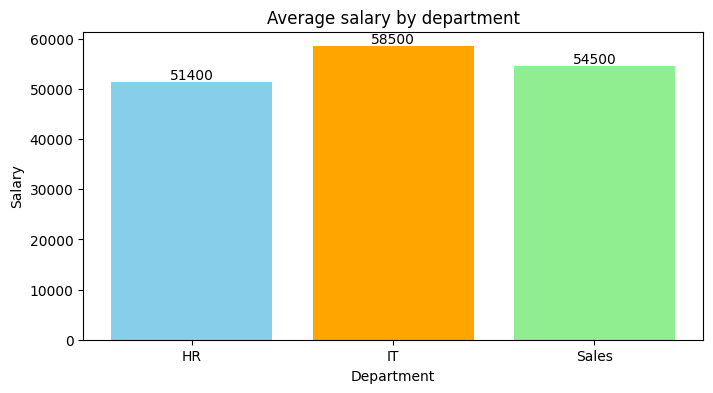

In [ ]:
avg = clean.groupby("Department")["Salary"].mean()

bars = plt.bar(avg.index, avg.values, color=["skyblue", "orange", "lightgreen"])
plt.bar_label(bars, fmt="%.0f")      # writes each bar's value on top

plt.title("Average salary by department")
plt.xlabel("Department")
plt.ylabel("Salary")
plt.show()

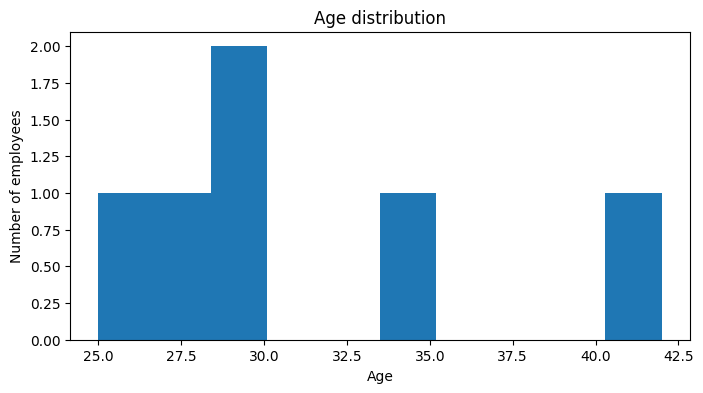

In [ ]:
# Histogram: shows how values are spread out
# The x-axis is divided into groups (bins); each bar's height is how many people fall in that group
plt.hist(clean["Age"])
plt.title("Age distribution")
plt.xlabel("Age")
plt.ylabel("Number of employees")
plt.show()

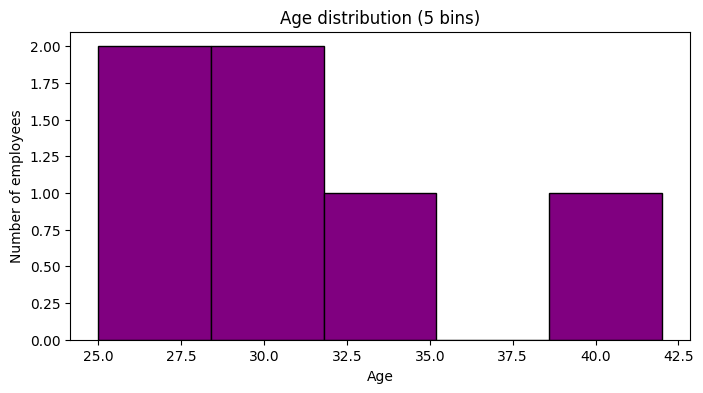

In [ ]:
# bins = how many groups to divide the data into
# color = bar colour, edgecolor = outline around each bar
plt.hist(clean["Age"], bins=5, color="purple", edgecolor="black")
plt.title("Age distribution (5 bins)")
plt.xlabel("Age")
plt.ylabel("Number of employees")
plt.show()

**Why do the two histograms look different?** The first used matplotlib's default of **10 bins** (each 1.7 years wide); the second used **5 bins** (each 3.4 years wide). With wider bins, ages 25 and 28 fall into the same group.
The number of bins changes the **shape** of a histogram: too many and it looks spiky, too few and it hides detail. Run the cell below to see the exact bin edges and counts.

Bin edges: [25.  28.4 31.8 35.2 38.6 42. ]
Counts   : [2. 2. 1. 0. 1.]


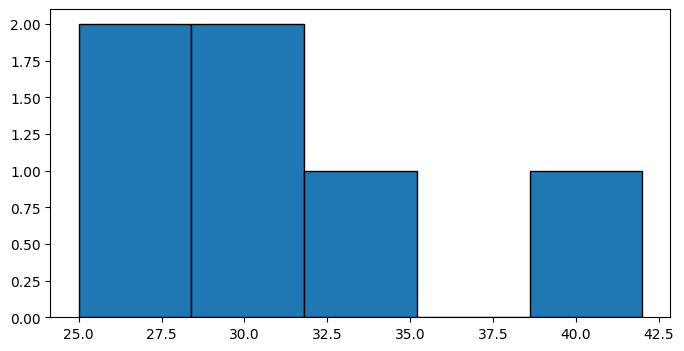

In [ ]:
counts, edges, _ = plt.hist(clean["Age"], bins=5, edgecolor="black")
print("Bin edges:", edges.round(1))
print("Counts   :", counts)
plt.show()

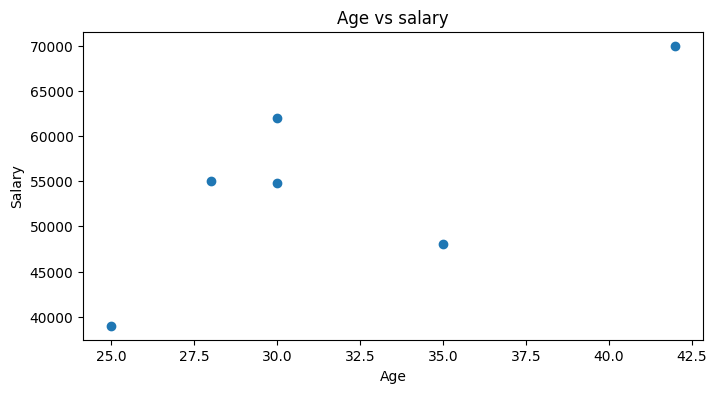

In [ ]:
# Scatter plot: shows the relationship between two number columns
# Each dot is one employee: x = Age, y = Salary
plt.scatter(clean["Age"], clean["Salary"])
plt.title("Age vs salary")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.show()

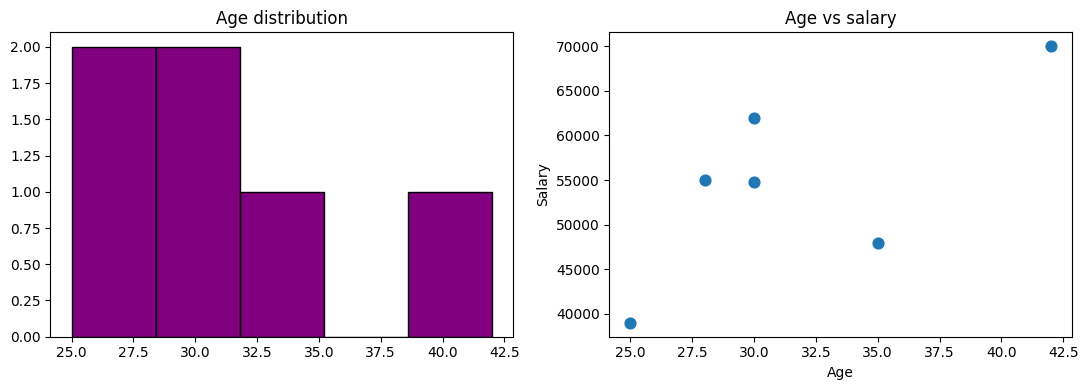

In [ ]:
# Two charts side by side with plt.subplots
# subplots(1, 2) = 1 row, 2 columns. ax1 is the left chart, ax2 the right chart
# With ax we use set_title / set_xlabel instead of plt.title / plt.xlabel
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.hist(clean["Age"], bins=5, color="purple", edgecolor="black")
ax1.set_title("Age distribution")

ax2.scatter(clean["Age"], clean["Salary"], s=60)
ax2.set_title("Age vs salary")
ax2.set_xlabel("Age")
ax2.set_ylabel("Salary")

plt.tight_layout()   # stops the charts from overlapping
plt.show()

### ✏️ Question 1.11a
Draw a **horizontal bar chart** (`plt.barh`) of each employee's salary in `clean`, sorted from lowest to highest, with a title.

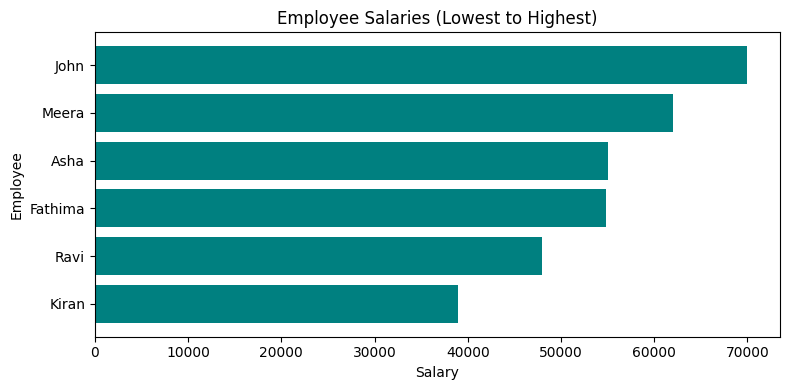

In [ ]:
sorted_sal = clean.sort_values("Salary", ascending=True)
plt.barh(sorted_sal["Name"], sorted_sal["Salary"], color="teal")
plt.title("Employee Salaries (Lowest to Highest)")
plt.xlabel("Salary")
plt.ylabel("Employee")
plt.tight_layout()
plt.show()

## 🧾 Recap: Attributes vs Methods vs Functions
| Attributes (no `()`) | Methods (`()`) | Functions (`pd.`) |
|---|---|---|
| `shape`, `size`, `columns`, `index`, `dtypes`, `values`, `is_unique` | `head`, `tail`, `info`, `describe`, `sum`, `mean`, `sort_values`, `value_counts`, `isnull`, `fillna`, `dropna`, `drop_duplicates`, `groupby`, `apply`, `map`, `rename`, `drop`, `astype` | `pd.Series`, `pd.DataFrame`, `pd.read_csv`, `pd.to_datetime`, `pd.concat`, `pd.get_dummies` |
| `.str` and `.dt` (accessors) | `.str.strip()`, `.str.title()`, `.dt.year`… | |

✅ **You're ready for the real project.**

---
# 📗 SECTION 2: The Churn Project
### ⬇️ Before you start
Download **`customer_churn.csv`** (shared by your instructor) and put it in the **same folder** as this notebook. Then continue below.

---
## Part A: Meet the Data 👋

### ✏️ Question A1
Load `customer_churn.csv` into a DataFrame called `df` and show the first 5 rows.

In [73]:
from google.colab import drive
import pandas as pd

drive.mount("/content/drive")
df = pd.read_csv("/content/drive/MyDrive/customer_churn.csv")
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,CustomerID,Name,Gender,Age,City,SignupDate,Plan,Contract,MonthlyCharges,TenureMonths,TotalCharges,SupportCalls,PaymentMethod,SeniorCitizen,SatisfactionScore,Churn
0,CUST1113,"Menon, Hari",Male,66.0,Bengaluru,09/07/2025,Standard,One year,521.61,13,6780.93,0,Debit Card,True,2.0,1
1,CUST1795,"Menon, Suresh",Male,18.0,KOLLAM,08/21/2026,Standard,One year,503.05,2,1006.10,2,Net Banking,False,1.0,1
2,CUST1817,"Menon, Arjun",NaN,74.0,Bengaluru,03/11/2023,Standard,One year,538.37,44,23688.28,3,UPI,True,4.0,0
3,CUST1510,"iyer, pooja",Female,66.0,Thiruvananthapuram,10/11/2025,Standard,Month-to-month,494.45,12,5933.40,2,Credit Card,True,NaN,0
4,CUST1492,"Krishnan, Gayathri",NaN,38.0,Kochi,05/19/2025,Standard,Month-to-month,520.10,17,8841.70,0,UPI,False,1.0,0


### ✏️ Question A2
How many rows and columns does the data have?

In [74]:
print("Rows and columns:", df.shape)

Rows and columns: (1012, 16)


### ✏️ Question A3
Use `info()` to see the data types and non-null counts. Which columns have missing values?

In [75]:
df.info()
print("\nColumns with missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1012 entries, 0 to 1011
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         1012 non-null   object 
 1   Name               1012 non-null   object 
 2   Gender             962 non-null    object 
 3   Age                971 non-null    float64
 4   City               982 non-null    object 
 5   SignupDate         1012 non-null   object 
 6   Plan               1012 non-null   object 
 7   Contract           1012 non-null   object 
 8   MonthlyCharges     1012 non-null   float64
 9   TenureMonths       1012 non-null   int64  
 10  TotalCharges       1012 non-null   float64
 11  SupportCalls       1012 non-null   int64  
 12  PaymentMethod      992 non-null    object 
 13  SeniorCitizen      971 non-null    object 
 14  SatisfactionScore  952 non-null    float64
 15  Churn              1012 non-null   int64  
dtypes: float64(4), int64(3),

### ✏️ Question A4
Write a **for loop** over `df.dtypes`: for `object` columns print `value_counts()` (top 5), for numeric columns print `describe()`.

In [76]:
for col, dtype in df.dtypes.items():
  print(f"=== {col} ({dtype}) ===")
  if dtype == "object":
    print(df[col].value_counts().head(5))
  else:
    print(df[col].describe())
  print()

=== CustomerID (object) ===
CustomerID
CUST1318    2
CUST1452    2
CUST1262    2
CUST1368    2
CUST1507    2
Name: count, dtype: int64

=== Name (object) ===
Name
Sharma, Aditya     5
Iyer, Sruthi       5
Das, Suresh        5
Iyer, Divya        5
Varma, Gayathri    5
Name: count, dtype: int64

=== Gender (object) ===
Gender
Female    492
Male      470
Name: count, dtype: int64

=== Age (float64) ===
count    971.000000
mean      45.666323
std       16.424959
min       18.000000
25%       32.000000
50%       46.000000
75%       59.500000
max       74.000000
Name: Age, dtype: float64

=== City (object) ===
City
Kochi                 164
Bengaluru              95
Thiruvananthapuram     87
Kozhikode              80
Kollam                 69
Name: count, dtype: int64

=== SignupDate (object) ===
SignupDate
08/28/2022    4
11/25/2020    3
09/07/2025    3
01/12/2024    3
09/25/2025    3
Name: count, dtype: int64

=== Plan (object) ===
Plan
Basic       456
Standard    345
Premium     211
Name:

### ✏️ Question A5
What percentage of customers churned (`Churn == 1`)?

In [77]:
churn_pct = df["Churn"].mean() * 100
print(f"Churn rate: {churn_pct:.2f}%")

Churn rate: 34.78%


💡 **Business insight:** In one sentence, how serious is the churn problem? Did you spot anything messy in the data?

> *Write your answer here (double-click to edit)*

---
## Part B: Data Cleaning 🧹
Real data is never clean. We'll fix it step by step, working on a copy called `data`.

### ✏️ Question B1
Make a copy: `data = df.copy()`. How many **duplicate rows** are there? Remove them and print the new shape.

In [78]:
data = df.copy()
print("Duplicate rows:", data.duplicated().sum())
data = data.drop_duplicates().copy()
print("New shape:", data.shape)


Duplicate rows: 12
New shape: (1000, 16)


In [79]:
# ✔️ Check your work (run this)
assert data.duplicated().sum() == 0, "There are still duplicates!"
print("✅ No duplicates")

✅ No duplicates


### ✏️ Question B2
Count the missing values in each column, and also show them as a percentage.

In [80]:
missing_count = data.isnull().sum()
missing_pct = (data.isnull().mean() * 100).round(2)
pd.DataFrame({"Missing": missing_count, "Percent (%)": missing_pct})

,Missing,Percent (%)
CustomerID,0,0.0
Name,0,0.0
Gender,50,5.0
Age,40,4.0
City,30,3.0
SignupDate,0,0.0
Plan,0,0.0
Contract,0,0.0
MonthlyCharges,0,0.0
TenureMonths,0,0.0


### ✏️ Question B3
The `City` and `Name` columns are messy (e.g. `'KOCHI'`, `'  kochi '`). Clean both with `str.strip()` and `str.title()`, then show `value_counts()` for `City`.

In [81]:
data["City"] = data["City"].str.strip().str.title()
data["Name"] = data["Name"].str.strip().str.title()
print(data["City"].value_counts(dropna=False))

City
Kochi                 246
Bengaluru             145
Thiruvananthapuram    145
Kozhikode             128
Thrissur              113
Kollam                100
Chennai                93
NaN                    30
Name: count, dtype: int64


### ✏️ Question B4
`SignupDate` is stored as text. Convert it to datetime (format `%m/%d/%Y`) and check its dtype.

In [82]:
data["SignupDate"] = pd.to_datetime(data["SignupDate"], format="%m/%d/%Y")
print(data["SignupDate"].dtype)

datetime64[ns]


### ✏️ Question B5
Fill the missing values: `Age` and `SatisfactionScore` with the **median**; `Gender`, `City` and `PaymentMethod` with the **mode**. Then recompute `SeniorCitizen` as `Age >= 60`.

**Work through it step by step:**

In [83]:
print(data.isnull().sum()[data.isnull().sum() > 0])

Gender               50
Age                  40
City                 30
PaymentMethod        20
SeniorCitizen        40
SatisfactionScore    60
dtype: int64


In [85]:
data["Age"] = data["Age"].fillna(data["Age"].median())

In [86]:
data["SatisfactionScore"] = data["SatisfactionScore"].fillna(data["SatisfactionScore"].median())

In [87]:
data["Gender"] = data["Gender"].fillna(data["Gender"].mode()[0])

In [88]:
data["City"] = data["City"].fillna(data["City"].mode()[0])

In [89]:
data["PaymentMethod"] = data["PaymentMethod"].fillna(data["PaymentMethod"].mode()[0])

In [90]:
data["SeniorCitizen"] = data["Age"] >= 60

In [91]:
print("Remaining missing values:", data.isnull().sum().sum())

Remaining missing values: 0


In [92]:
# ✔️ Check your work (run this)
assert data.isnull().sum().sum() == 0, "Missing values remain!"
print("✅ No missing values")

✅ No missing values


### ✏️ Question B6
Use the **IQR rule** to find outliers in `MonthlyCharges`. How many are there? Draw a boxplot of `MonthlyCharges`.

Number of outliers in MonthlyCharges: 7


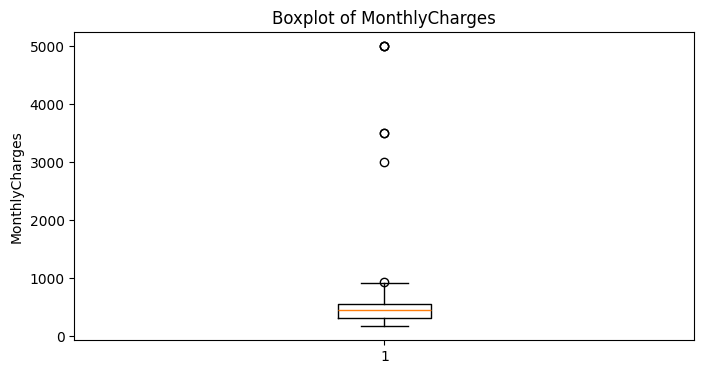

In [93]:
Q1 = data["MonthlyCharges"].quantile(0.25)
Q3 = data["MonthlyCharges"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = data[
    (data["MonthlyCharges"] < lower_bound)
    | (data["MonthlyCharges"] > upper_bound)
]
print("Number of outliers in MonthlyCharges:", len(outliers))

plt.boxplot(data["MonthlyCharges"])
plt.title("Boxplot of MonthlyCharges")
plt.ylabel("MonthlyCharges")
plt.show()

### ✏️ Question B7
Remove the outliers, recalculate `TotalCharges = MonthlyCharges × TenureMonths`, and print the final shape.

In [94]:
data = data[
    (data["MonthlyCharges"] >= lower_bound)
    & (data["MonthlyCharges"] <= upper_bound)
].copy()
data["TotalCharges"] = data["MonthlyCharges"] * data["TenureMonths"]
print("Final shape:", data.shape)

Final shape: (993, 16)


💡 **Business insight:** Summarise what you cleaned and why it matters before analysis.

> *Write your answer here (double-click to edit)*

---
## Part C: EDA, Answering the Manager's Questions 🔍
For each question: calculate the **churn rate per group** (`groupby(...)['Churn'].mean()`) and draw a chart.

### ✏️ Question C1
**Which contract type churns the most?** Show the churn rate by `Contract` as a bar chart.

Contract
Month-to-month    0.512241
One year          0.183824
Two year          0.136842
Name: Churn, dtype: float64


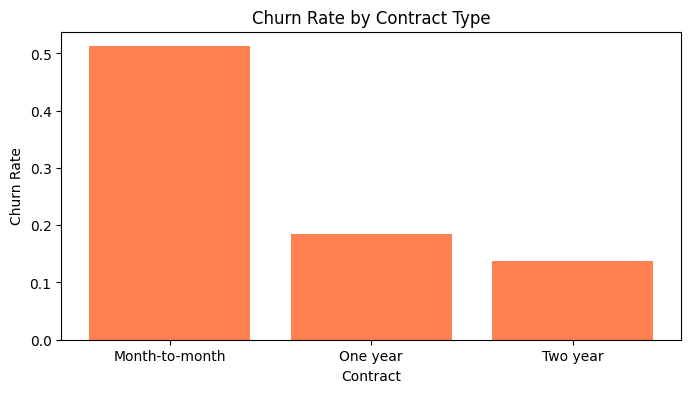

In [95]:
contract_churn = data.groupby("Contract")["Churn"].mean()
print(contract_churn)

plt.bar(contract_churn.index, contract_churn.values, color="coral")
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Churn Rate")
plt.show()

### ✏️ Question C2
**Do plan and payment method matter?** Make side-by-side bar charts of the churn rate by `Plan` and by `PaymentMethod`.

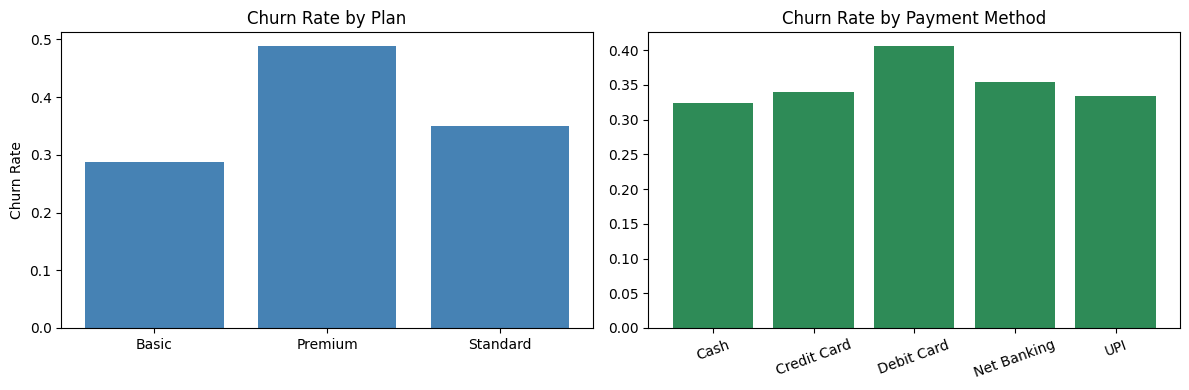

In [96]:
plan_churn = data.groupby("Plan")["Churn"].mean()
pay_churn = data.groupby("PaymentMethod")["Churn"].mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(plan_churn.index, plan_churn.values, color="steelblue")
ax1.set_title("Churn Rate by Plan")
ax1.set_ylabel("Churn Rate")

ax2.bar(pay_churn.index, pay_churn.values, color="seagreen")
ax2.set_title("Churn Rate by Payment Method")
ax2.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


### ✏️ Question C3
**Do unhappy customers call support more?** Compare the average `SupportCalls`, `SatisfactionScore`, `TenureMonths` and `MonthlyCharges` for churned vs stayed customers.

In [97]:
comparison = data.groupby("Churn")[
    ["SupportCalls", "SatisfactionScore", "TenureMonths", "MonthlyCharges"]
].mean()
print(comparison)

       SupportCalls  SatisfactionScore  TenureMonths  MonthlyCharges
Churn                                                               
0          1.282171           3.373643     41.150388      446.168016
1          1.853448           2.586207     27.801724      510.642701


### ✏️ Question C4
Plot the **churn rate for each number of support calls**. What pattern do you see?

SupportCalls
0    0.199115
1    0.305638
2    0.442553
3    0.470149
4    0.500000
5    0.600000
6    1.000000
Name: Churn, dtype: float64


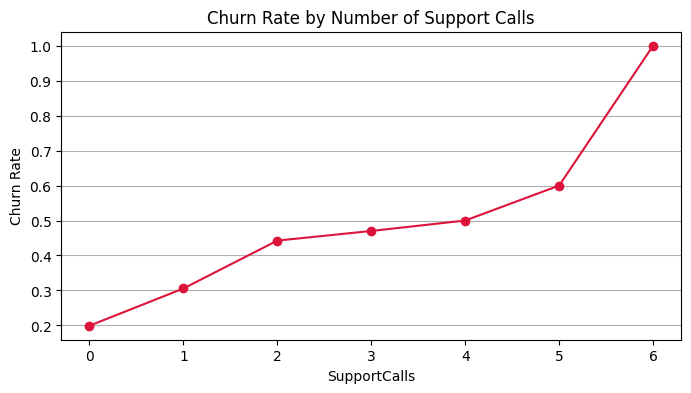

In [98]:
calls_churn = data.groupby("SupportCalls")["Churn"].mean()
print(calls_churn)

plt.plot(calls_churn.index, calls_churn.values, marker="o", color="crimson")
plt.title("Churn Rate by Number of Support Calls")
plt.xlabel("SupportCalls")
plt.ylabel("Churn Rate")
plt.grid(True, axis="y")
plt.show()

### ✏️ Question C5
**Does loyalty (tenure) matter?** Plot overlapping histograms of `TenureMonths` for churned and stayed customers.

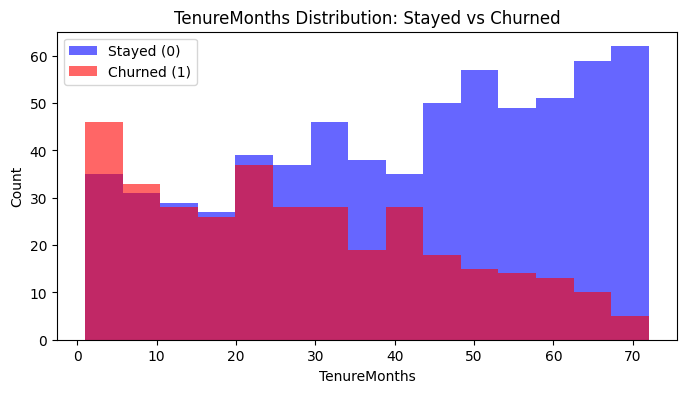

In [99]:
stayed_tenure = data[data["Churn"] == 0]["TenureMonths"]
churned_tenure = data[data["Churn"] == 1]["TenureMonths"]

plt.hist(stayed_tenure, bins=15, alpha=0.6, label="Stayed (0)", color="blue")
plt.hist(churned_tenure, bins=15, alpha=0.6, label="Churned (1)", color="red")
plt.title("TenureMonths Distribution: Stayed vs Churned")
plt.xlabel("TenureMonths")
plt.ylabel("Count")
plt.legend()
plt.show()

### ✏️ Question C6
**Satisfaction vs churn:** show the churn rate for each `SatisfactionScore` (1–5).

SatisfactionScore
1.0    0.513158
2.0    0.500000
3.0    0.366935
4.0    0.256545
5.0    0.151961
Name: Churn, dtype: float64


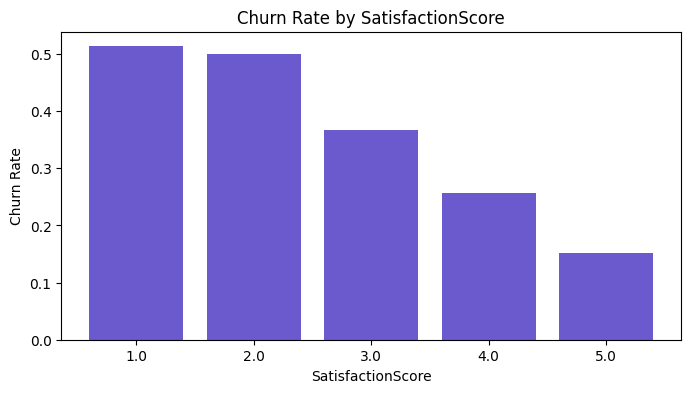

In [100]:
sat_churn = data.groupby("SatisfactionScore")["Churn"].mean()
print(sat_churn)

plt.bar(sat_churn.index.astype(str), sat_churn.values, color="slateblue")
plt.title("Churn Rate by SatisfactionScore")
plt.xlabel("SatisfactionScore")
plt.ylabel("Churn Rate")
plt.show()

### ✏️ Question C7
**Which city loses the most customers?** Show the number of customers, the number who churned, and the churn rate per city, sorted by churn rate.

In [101]:
city_stats = (
    data.groupby("City")
    .agg(
        Customers=("Churn", "count"),
        Churned=("Churn", "sum"),
        ChurnRate=("Churn", "mean"),
    )
    .sort_values("ChurnRate", ascending=False)
)
print(city_stats)

                    Customers  Churned  ChurnRate
City                                             
Bengaluru                 145       61   0.420690
Chennai                    92       34   0.369565
Kollam                     99       36   0.363636
Kochi                     274       99   0.361314
Kozhikode                 128       45   0.351562
Thrissur                  112       33   0.294643
Thiruvananthapuram        143       40   0.279720


### ✏️ Question C8
Make a **correlation heatmap** of the numeric columns. Which feature is most strongly linked with `Churn`?

Churn                1.000000
SupportCalls         0.225407
MonthlyCharges       0.158921
Age                  0.005644
TotalCharges        -0.155209
SatisfactionScore   -0.278772
TenureMonths        -0.306017
Name: Churn, dtype: float64


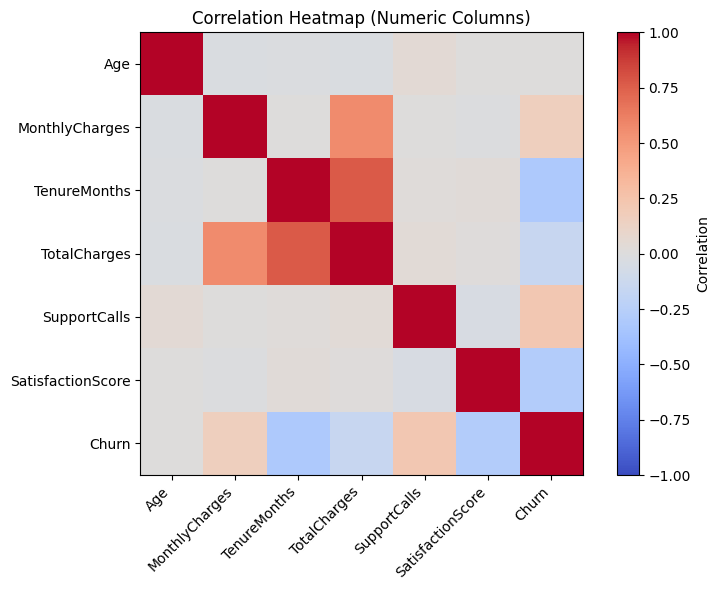

In [102]:
num_df = data.select_dtypes(include="number")
corr = num_df.corr()
print(corr["Churn"].sort_values(ascending=False))

plt.figure(figsize=(8, 6))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Heatmap (Numeric Columns)")
plt.tight_layout()
plt.show()


💡 **Business insight:** Write the top 3 reasons customers churn, based on your EDA.

> *Write your answer here (double-click to edit)*

---
## Part C2: Visualising with Matplotlib 📊
Pandas' `.plot()` is a shortcut. **Matplotlib** gives you full control, and it's what you'll use for reports and presentations.

**Cheat sheet**
| Chart | Function | Use it for |
|---|---|---|
| Bar | `plt.bar(x, height)` / `plt.barh` | Comparing categories |
| Histogram | `plt.hist(values, bins=)` | Distribution of one number |
| Box plot | `plt.boxplot([group1, group2])` | Spread and outliers by group |
| Scatter | `plt.scatter(x, y, c=)` | Relationship between two numbers |
| Line | `plt.plot(x, y, marker="o")` | Trends / ordered values |
| Pie | `plt.pie(sizes, labels=, autopct=)` | Parts of a whole |

**Every chart:** `plt.figure(figsize=)` → plot → `plt.title` / `plt.xlabel` / `plt.ylabel` → `plt.legend()` / `plt.grid()` → `plt.show()` (or `plt.savefig("file.png")`).

### ✏️ Question V1
**Figure anatomy:** use `plt.bar` to draw the number of customers who **stayed vs churned**. Add a title, axis labels, a grid on the y-axis, and give the bars different colours.

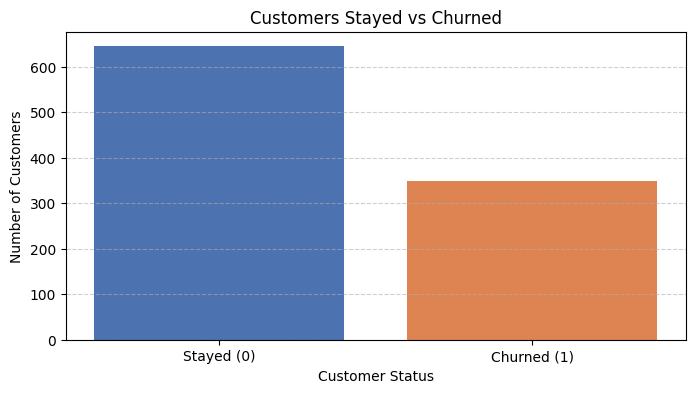

In [103]:
counts = data["Churn"].value_counts().sort_index()
plt.bar(["Stayed (0)", "Churned (1)"], counts.values, color=["#4C72B0", "#DD8452"])
plt.title("Customers Stayed vs Churned")
plt.xlabel("Customer Status")
plt.ylabel("Number of Customers")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

### ✏️ Question V2
**Bar chart with value labels:** plot the churn rate (%) by `Contract` and write each percentage on top of its bar.

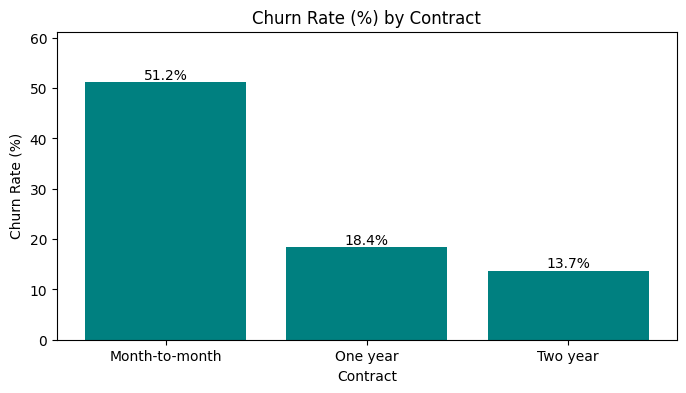

In [104]:
contract_pct = (data.groupby("Contract")["Churn"].mean() * 100).sort_values(
    ascending=False
)
bars = plt.bar(contract_pct.index, contract_pct.values, color="teal")
plt.bar_label(bars, fmt="%.1f%%")
plt.title("Churn Rate (%) by Contract")
plt.xlabel("Contract")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, contract_pct.max() + 10)
plt.show()

### ✏️ Question V3
**Grouped bar chart:** for each `Plan`, show the number of customers who stayed and who churned as two bars side by side.

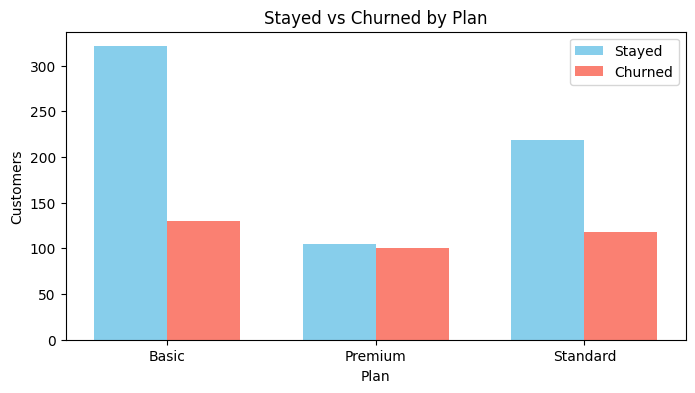

In [105]:
plan_ct = pd.crosstab(data["Plan"], data["Churn"])
x = np.arange(len(plan_ct.index))
width = 0.35

plt.bar(x - width / 2, plan_ct[0], width, label="Stayed", color="skyblue")
plt.bar(x + width / 2, plan_ct[1], width, label="Churned", color="salmon")
plt.xticks(x, plan_ct.index)
plt.title("Stayed vs Churned by Plan")
plt.xlabel("Plan")
plt.ylabel("Customers")
plt.legend()
plt.show()

### ✏️ Question V4
**Histogram:** draw overlapping histograms of `TenureMonths` for stayed and churned customers (use `alpha` and a legend).

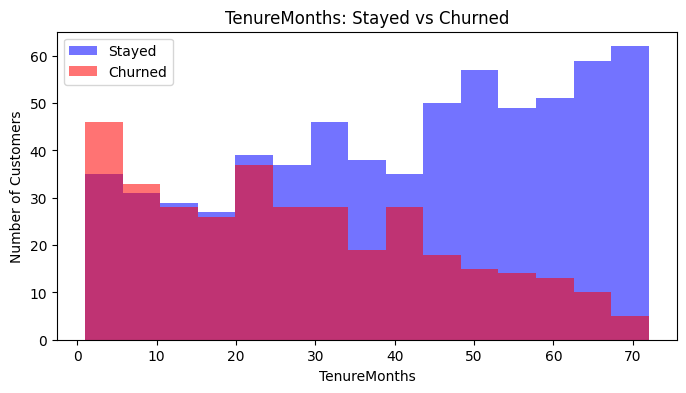

In [106]:
plt.hist(
    data[data["Churn"] == 0]["TenureMonths"],
    bins=15,
    alpha=0.55,
    label="Stayed",
    color="blue",
)
plt.hist(
    data[data["Churn"] == 1]["TenureMonths"],
    bins=15,
    alpha=0.55,
    label="Churned",
    color="red",
)
plt.title("TenureMonths: Stayed vs Churned")
plt.xlabel("TenureMonths")
plt.ylabel("Number of Customers")
plt.legend()
plt.show()

### ✏️ Question V5
**Box plot:** compare `MonthlyCharges` across the three plans with `plt.boxplot`.

/tmp/ipykernel_1165/1170300106.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=plans)


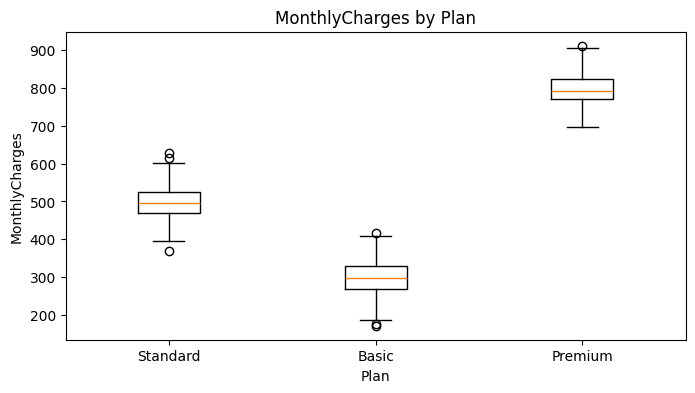

In [107]:
plans = data["Plan"].unique()
groups = [data[data["Plan"] == p]["MonthlyCharges"] for p in plans]

plt.boxplot(groups, labels=plans)
plt.title("MonthlyCharges by Plan")
plt.xlabel("Plan")
plt.ylabel("MonthlyCharges")
plt.show()

### ✏️ Question V6
**Scatter plot:** plot `TenureMonths` (x) vs `MonthlyCharges` (y), red for churned and blue for stayed. Where do the churners cluster?

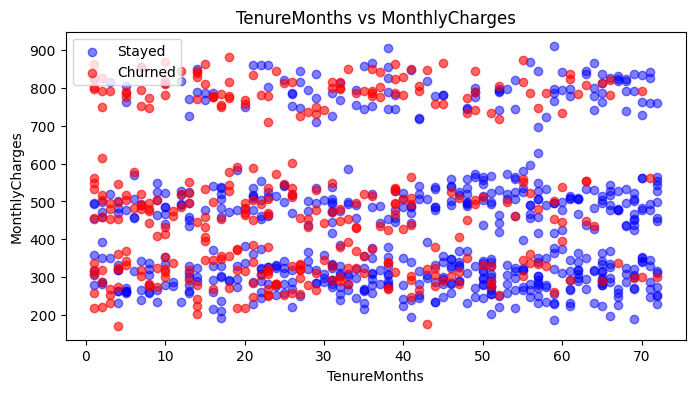

In [108]:
stayed = data[data["Churn"] == 0]
churned = data[data["Churn"] == 1]

plt.scatter(
    stayed["TenureMonths"],
    stayed["MonthlyCharges"],
    c="blue",
    alpha=0.5,
    label="Stayed",
)
plt.scatter(
    churned["TenureMonths"],
    churned["MonthlyCharges"],
    c="red",
    alpha=0.6,
    label="Churned",
)
plt.title("TenureMonths vs MonthlyCharges")
plt.xlabel("TenureMonths")
plt.ylabel("MonthlyCharges")
plt.legend()
plt.show()

### ✏️ Question V7
**Pie + line in one figure:** using `plt.subplots(1, 2)`, draw (left) a pie of the churn split with percentages and (right) a line chart of churn rate by `SatisfactionScore`.

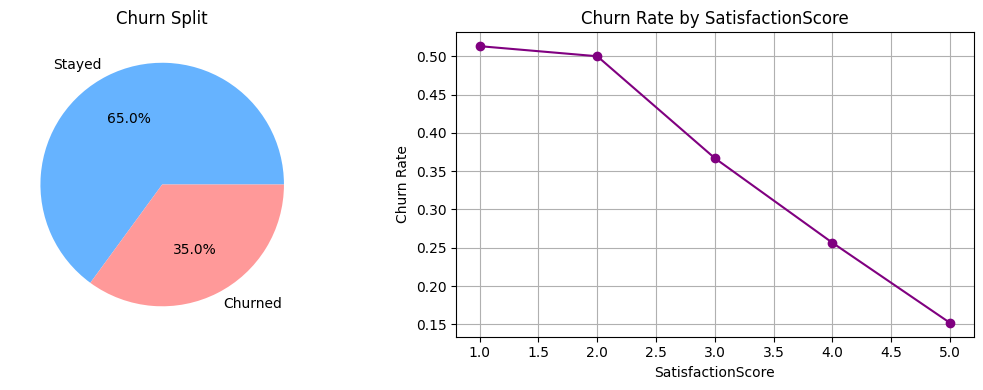

In [109]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

churn_counts = data["Churn"].value_counts().sort_index()
ax1.pie(
    churn_counts.values,
    labels=["Stayed", "Churned"],
    autopct="%1.1f%%",
    colors=["#66b3ff", "#ff9999"],
)
ax1.set_title("Churn Split")

sat_rate = data.groupby("SatisfactionScore")["Churn"].mean()
ax2.plot(
    sat_rate.index,
    sat_rate.values,
    marker="o",
    color="purple",
)
ax2.set_title("Churn Rate by SatisfactionScore")
ax2.set_xlabel("SatisfactionScore")
ax2.set_ylabel("Churn Rate")
ax2.grid(True)

plt.tight_layout()
plt.show()

### ✏️ Question V8
📊 **Manager dashboard:** build a 2×2 figure with `plt.subplots(2, 2)` showing (1) churn rate by contract, (2) churn rate by support calls, (3) tenure histograms for churned vs stayed, (4) churn rate by payment method. Give it an overall title with `fig.suptitle` and save it as `churn_dashboard.png`.

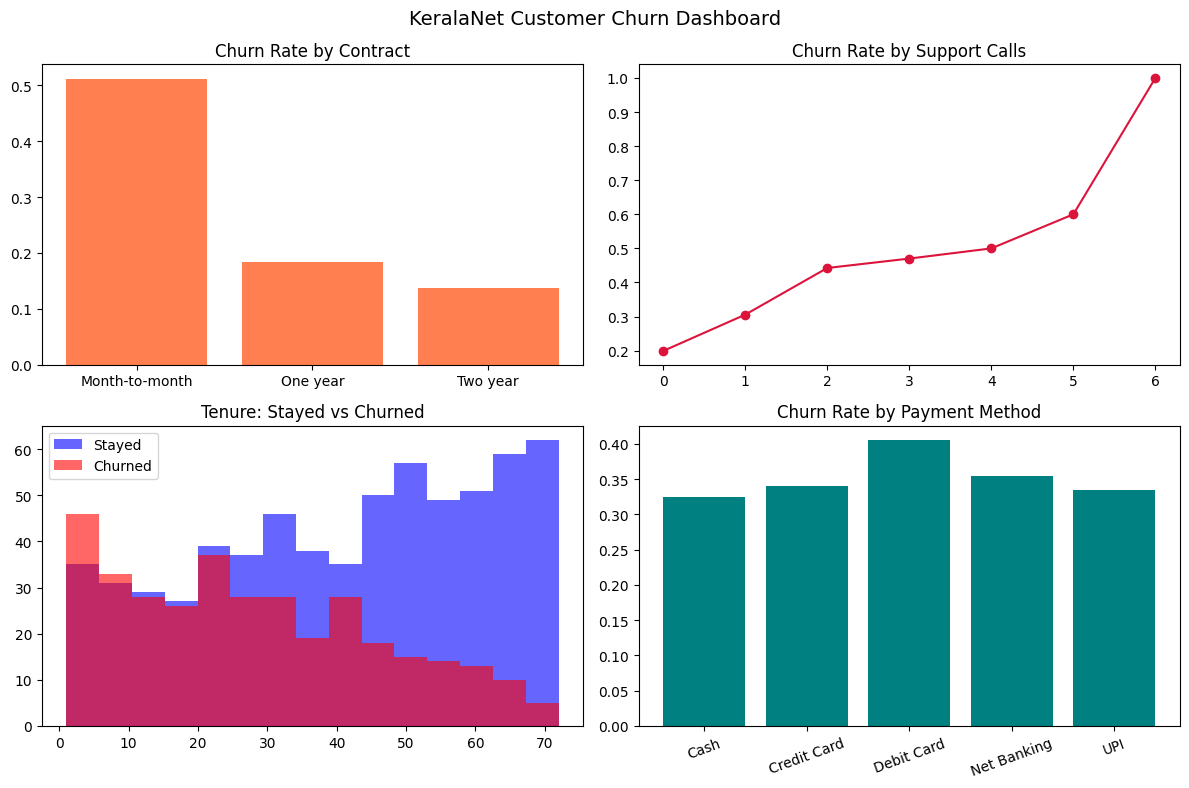

In [110]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

c_rate = data.groupby("Contract")["Churn"].mean()
axes[0, 0].bar(c_rate.index, c_rate.values, color="coral")
axes[0, 0].set_title("Churn Rate by Contract")

sc_rate = data.groupby("SupportCalls")["Churn"].mean()
axes[0, 1].plot(sc_rate.index, sc_rate.values, marker="o", color="crimson")
axes[0, 1].set_title("Churn Rate by Support Calls")

axes[1, 0].hist(
    data[data["Churn"] == 0]["TenureMonths"],
    bins=15,
    alpha=0.6,
    label="Stayed",
    color="blue",
)
axes[1, 0].hist(
    data[data["Churn"] == 1]["TenureMonths"],
    bins=15,
    alpha=0.6,
    label="Churned",
    color="red",
)
axes[1, 0].set_title("Tenure: Stayed vs Churned")
axes[1, 0].legend()

pm_rate = data.groupby("PaymentMethod")["Churn"].mean()
axes[1, 1].bar(pm_rate.index, pm_rate.values, color="teal")
axes[1, 1].set_title("Churn Rate by Payment Method")
axes[1, 1].tick_params(axis="x", rotation=20)

fig.suptitle("KeralaNet Customer Churn Dashboard", fontsize=14)
plt.tight_layout()
plt.savefig("churn_dashboard.png")
plt.show()

💡 **Business insight:** Which chart would you put on the first slide for your manager, and why?

> *Write your answer here (double-click to edit)*

---
## Part D: Prepare the Data for a Model 🛠️
A model needs **numbers only**, a clear **target**, and separate **train** and **test** data.

### ✏️ Question D1
Create `X` from the features `TenureMonths`, `MonthlyCharges`, `SupportCalls`, `SatisfactionScore`, `Age`, `Contract`, `Plan`, `PaymentMethod`, and set `y = data['Churn']`.

In [111]:
feature_cols = [
    "TenureMonths",
    "MonthlyCharges",
    "SupportCalls",
    "SatisfactionScore",
    "Age",
    "Contract",
    "Plan",
    "PaymentMethod",
]
X = data[feature_cols].copy()
y = data["Churn"].copy()

### ✏️ Question D2
Models can't read text. **One-hot encode** `Contract`, `Plan` and `PaymentMethod` with `pd.get_dummies(..., drop_first=True, dtype=int)`.

In [112]:
X = pd.get_dummies(
    X, columns=["Contract", "Plan", "PaymentMethod"], drop_first=True, dtype=int)
X.head()

,TenureMonths,MonthlyCharges,SupportCalls,SatisfactionScore,Age,Contract_One year,Contract_Two year,Plan_Premium,Plan_Standard,PaymentMethod_Credit Card,PaymentMethod_Debit Card,PaymentMethod_Net Banking,PaymentMethod_UPI
0,13,521.61,0,2.0,66.0,1,0,0,1,0,1,0,0
1,2,503.05,2,1.0,18.0,1,0,0,1,0,0,1,0
2,44,538.37,3,4.0,74.0,1,0,0,1,0,0,0,1
3,12,494.45,2,3.0,66.0,0,0,0,1,1,0,0,0
4,17,520.10,0,1.0,38.0,0,0,0,1,0,0,0,1


### ✏️ Question D3
Split the data 80/20 into train and test sets with `train_test_split` (`random_state=42`, `stratify=y`).

In [113]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Train shape:", X_train.shape, "Test shape:", X_test.shape)

Train shape: (794, 13) Test shape: (199, 13)


### ✏️ Question D4
**Scale** the features with `StandardScaler`: `fit_transform` on the training set, `transform` on the test set.

In [114]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### ✏️ Question D5
Check that the churn ratio is similar in `y_train` and `y_test`.

In [116]:
print("Train churn ratio:", round(y_train.mean(), 4))
print("Test churn ratio :", round(y_test.mean(), 4))

Train churn ratio: 0.3501
Test churn ratio : 0.3518


---
## Part E: Logistic Regression 🤖
Logistic regression outputs a **probability of churn** between 0 and 1. If it's ≥ 0.5, we predict **churn**.

### ✏️ Question E1
Create a `LogisticRegression()` model and fit it on the scaled training data.

In [117]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train_scaled, y_train)

LogisticRegression()

### ✏️ Question E2
Predict on the test set. Show a table of the first 10 rows with **Actual**, **Predicted** and **P(churn)**.

In [118]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "P(churn)": y_prob.round(3),
})
results.head(10)

,Actual,Predicted,P(churn)
0,0,0,0.074
1,0,0,0.019
2,1,1,0.922
3,0,0,0.113
4,0,1,0.614
5,0,0,0.402
6,0,0,0.072
7,0,1,0.647
8,0,0,0.026
9,1,1,0.727


### ✏️ Question E3
Print the **accuracy** and the **classification report**, and plot the **confusion matrix**.

In [119]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

Accuracy: 0.7789

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.86      0.83       129
           1       0.71      0.63      0.67        70

    accuracy                           0.78       199
   macro avg       0.76      0.74      0.75       199
weighted avg       0.77      0.78      0.78       199

Confusion Matrix:
 [[111  18]
 [ 26  44]]


### ✏️ Question E3b
**Confusion matrix in plain matplotlib:** draw it yourself with `plt.imshow` and write each count in its cell.

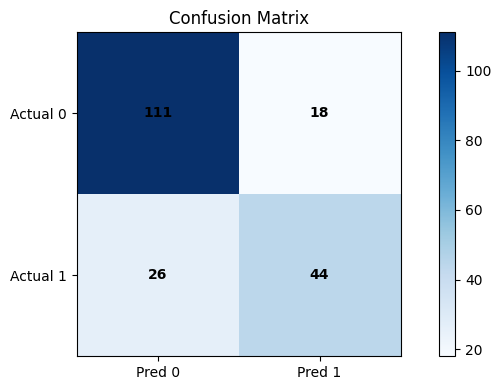

In [120]:
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks([0, 1], ["Pred 0", "Pred 1"])
plt.yticks([0, 1], ["Actual 0", "Actual 1"])
plt.title("Confusion Matrix")

for i in range(cm.shape[0]):
  for j in range(cm.shape[1]):
    plt.text(
        j,
        i,
        str(cm[i, j]),
        ha="center",
        va="center",
        color="black",
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

### ✏️ Question E4
Show the model's **coefficients** as a sorted horizontal bar chart. Which features push churn up, and which pull it down?

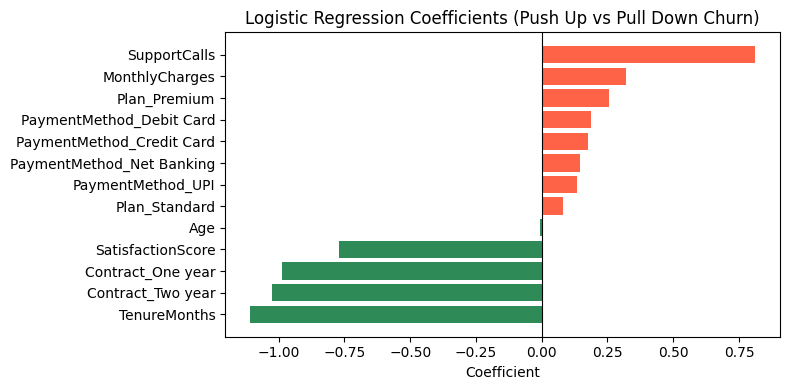

In [121]:
coef_df = pd.DataFrame(
    {"Feature": X.columns, "Coefficient": model.coef_[0]}
).sort_values("Coefficient")

plt.barh(
    coef_df["Feature"],
    coef_df["Coefficient"],
    color=np.where(coef_df["Coefficient"] > 0, "tomato", "seagreen"),
)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic Regression Coefficients (Push Up vs Pull Down Churn)")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

### ✏️ Question E5
🎯 **Predict for a new customer:** 3 months tenure, ₹550 per month, 4 support calls, satisfaction 2, age 30, month-to-month contract, Standard plan, pays by UPI. What is their churn probability?

In [123]:
new_customer = pd.DataFrame([{
    "TenureMonths": 3,
    "MonthlyCharges": 550,
    "SupportCalls": 4,
    "SatisfactionScore": 2,
    "Age": 30,
    "Contract": "Month-to-month",
    "Plan": "Standard",
    "PaymentMethod": "UPI",
}])
new_customer_enc = pd.get_dummies( new_customer,columns=["Contract", "Plan", "PaymentMethod"],drop_first=True,dtype=int,)
new_customer_enc = new_customer_enc.reindex(columns=X.columns, fill_value=0)
new_customer_scaled = scaler.transform(new_customer_enc)

prob_churn = model.predict_proba(new_customer_scaled)[0, 1]
print(f"Predicted churn probability: {prob_churn:.4f} ({prob_churn*100:.2f}%)")

Predicted churn probability: 0.9756 (97.56%)


💡 **Business insight:** Is this model useful to the manager? What does it get right, and what does it miss?

> *Write your answer here (double-click to edit)*

---
## Part F: Recommendations & Challenges 🚀

### ✏️ Question F1
Write **3 recommendations** for the manager as a markdown cell or `print` statements, based on your analysis.

In [124]:
print("1. Incentivise longer contracts (1-year/2-year) with discounts or perks for month-to-month users.")
print("2. Trigger proactive outreach after 2+ support calls or low satisfaction scores (1-2).")
print("3. Focus onboarding support in the first few months when tenure is low and churn risk is highest.")

1. Incentivise longer contracts (1-year/2-year) with discounts or perks for month-to-month users.
2. Trigger proactive outreach after 2+ support calls or low satisfaction scores (1-2).
3. Focus onboarding support in the first few months when tenure is low and churn risk is highest.


### ⭐ Challenge questions (optional)

### ✏️ Question F2
**Threshold tuning:** predict churn when P(churn) ≥ **0.35** instead of 0.5. How do recall and precision for churners change?

In [ ]:
# YOUR CODE HERE


### ✏️ Question F3
**Remove a feature:** retrain without the `Contract` columns. How much does accuracy drop? What does that tell you?

In [ ]:
# YOUR CODE HERE


### ✏️ Question F4
**Try another model:** fit a `DecisionTreeClassifier(max_depth=4, random_state=42)` and compare its accuracy.

In [ ]:
# YOUR CODE HERE


---
## 🎉 Well done!
You just completed a real data-analysis workflow: **load → clean → explore → prepare → model → recommend**. This is what data analysts and data scientists do every day.

**Next ideas:** try this workflow on a dataset you care about (cricket stats, Kerala rainfall, movie ratings from Kaggle), or learn more models (random forests, XGBoost).